In [ ]:
# mayplotlib animation动画
# 完成时间：2026-6-28
# 练习内容： 利用matplotlib制作动图

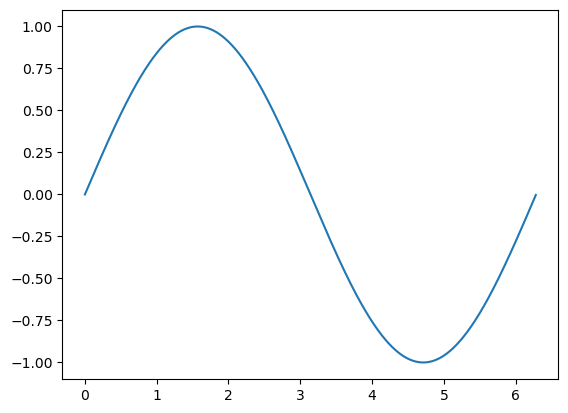

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import animation

fig, ax = plt.subplots()

x = np.arange(0, 2*np.pi, 0.01)
line, = ax.plot(x, np.sin(x)) # 绘制初始正弦曲线，逗号, 代表只接收plot返回的线条对象

# 定义动画更新函数：每一帧都会自动调用这个函数，i为当前帧序号
def animate(i):
    # 更新线条的y轴数据：x整体偏移 i/10，实现正弦波向右平移
    line.set_ydata(np.sin(x + i/10.0))  # update the data
    return line,


# 仅在开启blit局部重绘时需要，用来清空画布、初始化画面
def init():
     # 初始化线条数据，恢复原始无偏移的正弦曲线
    line.set_ydata(np.sin(x))
    return line,

# 调用动画生成器。blit=True代表只重绘画面中发生变化的区域，提升渲染速度
# blit=True在Mac系统无法正常运行，此时请设置blit=False
# interval 控制帧与帧之间的刷新间隔（单位：毫秒）
ani = animation.FuncAnimation(fig=fig, func=animate, frames=100, init_func=init, # 创建动画实例ani fig：绑定动画的画布；func=animate：每一帧执行的更新函数
# frames=100：总帧数100帧；init_func=init：动画启动前执行的初始化函数 interval=20：帧间隔20ms，即每秒刷新50次；blit=False：关闭局部重绘，全平台兼容
                              interval=20, blit=False)

# 将动画保存为mp4视频文件。该功能需要提前安装ffmpeg或mencoder解码器
# extra_args参数指定使用x264编码，生成的视频可以嵌入html5网页
# 不同电脑环境可能需要修改参数，更多文档参考官网地址
# http://matplotlib.sourceforge.net/api/animation_api.html
# anim.save('basic_animation.mp4', fps=30, extra_args=['-vcodec', 'libx264'])

plt.show()